# A/B-тест алгоритма рекомендаций

**Задача:** оценить, как новая рекомендательная механика повлияла на CTR ленты новостей и стоит ли запускать её на всех пользователей.

**Данные:** события `view` и `like` из ClickHouse за 29 мая – 4 июня 2026 года, контрольная группа 1, тестовая группа 2.

**Итог:** средний пользовательский CTR не показал значимых различий, но анализ бакетного и общего CTR выявил снижение в тестовой группе. Массовый запуск не рекомендован.

Ниже сохранены код, статистические результаты и графики исходного анализа. Параметры доступа удалены. Без учебной базы повторный запуск невозможен; выводы сформулированы с учётом различий между метриками.


In [2]:
import pandas as pd
import pandahouse as ph
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

In [3]:
# Исходная учебная база недоступна. Для повторного запуска нужны свои параметры подключения.
# Секреты не хранятся в ноутбуке и не публикуются в репозитории.
import os

required = ('CLICKHOUSE_HOST', 'CLICKHOUSE_USER', 'CLICKHOUSE_PASSWORD')
missing = [key for key in required if not os.getenv(key)]
if missing:
    raise RuntimeError('Нет переменных окружения: ' + ', '.join(missing))

connection = {
    'host': os.environ['CLICKHOUSE_HOST'],
    'user': os.environ['CLICKHOUSE_USER'],
    'password': os.environ['CLICKHOUSE_PASSWORD'],
    'database': os.getenv('CLICKHOUSE_DATABASE', 'simulator_20260620')
}


In [4]:
q = """
SELECT exp_group, 
       user_id,
       sum(action = 'like') as likes,
       sum(action = 'view') as views,
       likes/views as ctr
FROM {db}.feed_actions 
WHERE toDate(time) between '2026-05-29' and '2026-06-04'
  and exp_group in (1,2)
GROUP BY exp_group, user_id
"""

In [5]:
df = ph.read_clickhouse(q, connection=connection)
df

In [6]:
# Разделяем на контрольную (группа 1) и тестовую (группа 2) группы

ctr_control = df[df.exp_group == 1]['ctr']
ctr_test = df[df.exp_group == 2]['ctr']

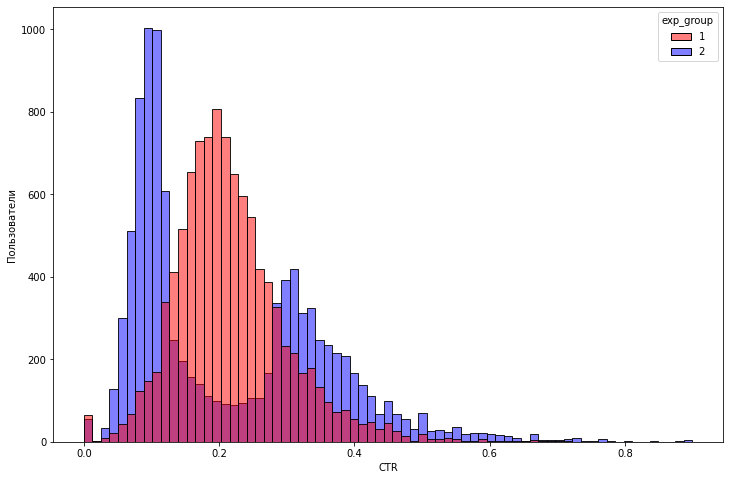

In [7]:
# Посмотрим на распределение глазами

plt.figure(figsize=(12, 8))
sns.histplot(data=df, x='ctr', hue='exp_group', palette = ['r', 'b'], kde=False)
plt.xlabel('CTR')
plt.ylabel('Пользователи')
plt.show()

В контрольной группе распределение пользовательского CTR сосредоточено около 0,2. В тестовой группе заметны два пика, примерно около 0,1 и 0,3. Это может говорить о неоднородности пользовательской активности. Чтобы понять причины такой формы распределения, нужен дополнительный анализ по сегментам.


### t-тест пользовательского CTR

Нулевая гипотеза: средний пользовательский CTR в двух группах одинаков. Альтернативная: средние различаются. Для сравнения применяется t-тест Уэлча.


In [8]:
stats.ttest_ind(ctr_control, ctr_test, equal_var=False)

Ttest_indResult(statistic=0.4051491913112757, pvalue=0.685373331140751)

Получено p-value = 0,685. При уровне значимости 5% **нет оснований отвергнуть нулевую гипотезу** о равенстве среднего пользовательского CTR. Это не доказывает, что различий вообще нет.

Бимодальное распределение тестовой группы заслуживает отдельного внимания, но само по себе не делает t-тест некорректным. Для проверки выводов дополнительно рассматриваются другие метрики и методы.


### Бакетное преобразование

Пользователи объединяются в 50 бакетов по хешу `user_id`. Для каждого бакета рассчитывается отношение суммарных лайков к суммарным просмотрам. Так получается **бакетный CTR**, который отличается от среднего индивидуальных CTR: пользователи с большим количеством просмотров сильнее влияют на результат.

Затем бакетные CTR сравниваются t-тестом.


In [9]:
# Вытаскиваем бакетный CTR кликхауса

q_buckets = """
SELECT exp_group, 
       bucket,
       sum(likes) / sum(views) as bucket_ctr
FROM (
    SELECT exp_group, 
           xxHash64(user_id) % 50 as bucket,
           user_id,
           sum(action = 'like') as likes,
           sum(action = 'view') as views
    FROM {db}.feed_actions 
    WHERE toDate(time) between '2026-05-29' and '2026-06-04'
      and exp_group in (1,2)
    GROUP BY exp_group, bucket, user_id
)
GROUP BY exp_group, bucket
"""

In [10]:
df_buckets = ph.read_clickhouse(q_buckets, connection=connection)
df_buckets

,exp_group,bucket,bucket_ctr
0,1,0,0.200592
1,2,0,0.196510
2,1,1,0.208799
3,2,1,0.210375
4,1,2,0.204632
...,...,...,...
95,2,47,0.196808
96,1,48,0.216369
97,2,48,0.194780
98,1,49,0.206288


In [11]:
# Разделяем бакеты по группам
buckets_control = df_buckets[df_buckets.exp_group == 1].bucket_ctr
buckets_test = df_buckets[df_buckets.exp_group == 2].bucket_ctr

In [12]:
# Запускаем t-тест поверх бакетов
stats.ttest_ind(buckets_control, buckets_test, equal_var=False)

Ttest_indResult(statistic=5.614819358149381, pvalue=4.592644937473873e-07)

<Axes: xlabel='bucket_ctr', ylabel='Count'>

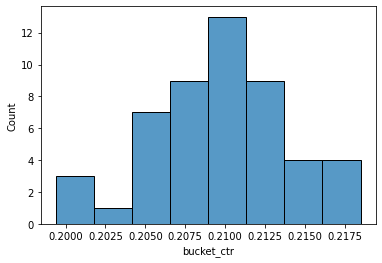

In [14]:
sns.histplot(buckets_control)

<Axes: xlabel='bucket_ctr', ylabel='Count'>

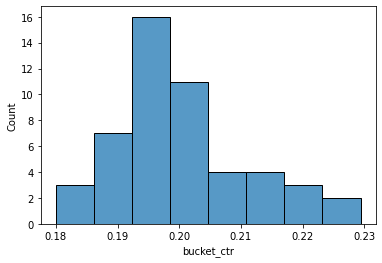

In [15]:
sns.histplot(buckets_test)

### Bootstrap  общего CTR

Для каждого пользователя генерируются пуассоновские веса. По ним рассчитывается общий CTR группы как отношение взвешенной суммы лайков к взвешенной сумме просмотров. В сохранённом запуске выполнено 2000 бутстрэп-итераций.

Здесь оценивается **общий CTR**, а не среднее пользовательских CTR. Поэтому результат может отличаться от первого t-теста.


In [18]:
def bootstrap(likes1, views1, likes2, views2, n_bootstrap=2000):

    poisson_bootstraps1 = stats.poisson(1).rvs(
        (n_bootstrap, len(likes1))).astype(np.int64)

    poisson_bootstraps2 = stats.poisson(1).rvs(
            (n_bootstrap, len(likes2))).astype(np.int64)
    
    globalCTR1 = (poisson_bootstraps1*likes1).sum(axis=1)/(poisson_bootstraps1*views1).sum(axis=1)
    
    globalCTR2 = (poisson_bootstraps2*likes2).sum(axis=1)/(poisson_bootstraps2*views2).sum(axis=1)

    return globalCTR1, globalCTR2


In [19]:
q_bootstrap = """
SELECT exp_group, 
    user_id,
    sum(action = 'like') as likes,
    sum(action = 'view') as views,
    likes/views as ctr
FROM {db}.feed_actions 
WHERE toDate(time) between '2026-05-29' and '2026-06-04'
    and exp_group in (1,2)
GROUP BY exp_group, user_id
"""

In [20]:
df_bootstrap = ph.read_clickhouse(q_bootstrap, connection=connection)

In [21]:
likes1 = df_bootstrap[df_bootstrap.exp_group == 1].likes.to_numpy()
views1 = df_bootstrap[df_bootstrap.exp_group == 1].views.to_numpy()
likes2 = df_bootstrap[df_bootstrap.exp_group == 2].likes.to_numpy()
views2 = df_bootstrap[df_bootstrap.exp_group == 2].views.to_numpy()

ctr1, ctr2 = bootstrap(likes1, views1, likes2, views2)

<Axes: ylabel='Count'>

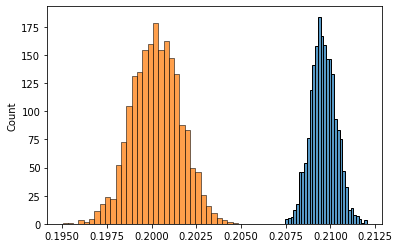

In [23]:
sns.histplot(ctr1)
sns.histplot(ctr2)

На графике сохранённого запуска распределение общего CTR тестовой группы находится левее контрольной, то есть значение метрики в тесте ниже.


<Axes: ylabel='Count'>

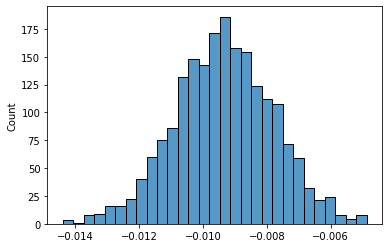

In [24]:
sns.histplot(ctr2 - ctr1)

In [30]:
# Находим разность между тестом и контролем
ctr_diff = ctr2 - ctr1

# Считаем 95% доверительный интервал
ci_lower = np.percentile(ctr_diff, 2.5)
ci_upper = np.percentile(ctr_diff, 97.5)
print(ci_lower, ci_upper)

-0.012454982112064132 -0.006298631566310601


95% бутстрэп-интервал для разности общего CTR **(тест минус контроль)**: от −0,01245 до −0,00630, или примерно от **−1,25 до −0,63 процентного пункта**. Интервал целиком ниже нуля, что указывает на снижение общего CTR в тестовой группе в рамках этого анализа.


## Выводы


**Распределение CTR.** В тестовой группе пользовательский CTR имеет два заметных пика. Это основание проверить эффект алгоритма на отдельных сегментах, но по одной гистограмме нельзя определить, какие именно пользователи выиграли или проиграли от изменения.


**Сравнение методов.** t-тест пользовательского CTR не выявил статистически значимого различия средних (p = 0,685). Тест бакетного CTR показал значимое различие (p ≈ 4,59 × 10⁻⁷), а Bootstrap  подтвердил снижение общего CTR. Методы оценивают не одну и ту же метрику, поэтому результаты не обязательно противоречат друг другу.


**Размер изменения.** 95% бутстрэп-интервал разности общего CTR находится в диапазоне от −1,25 до −0,63 процентного пункта. Это отрицательное изменение метрики в тестовой группе на доступных данных.


**Возможные причины.** Бимодальность может быть связана с различиями между сегментами, неодинаковой частотой просмотров или поведением пользователей. График не позволяет подтвердить конкретную причину. Для продолжения исследования полезно сравнить сегменты и проверить изменения CTR с учётом интенсивности активности.


**Рекомендация.** Не запускать новый алгоритм рекомендаций на всех пользователей по результатам этого эксперимента. Значимое улучшение не подтверждено, а общий CTR в тестовой группе снизился. Перед повторным тестированием стоит разобраться в неоднородности пользовательского CTR и причинах отрицательного результата.
